In [ ]:
!pip install pymorphy3
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 12.7 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import random
import re
import gc

import pymorphy3
from functools import lru_cache

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchmetrics.classification import MulticlassAccuracy, MulticlassF1Score

In [ ]:
# Загрузка датасета с Hugging Face
from datasets import load_dataset

dataset = load_dataset("k1tub/sentiment_dataset")

print(dataset['train'][0])

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/3.02k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/96.1M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/290458 [00:00<?, ? examples/s]

{'text': 'Пальто красивое, но пришло с дырой в молнии. Просила выслать такую же, но продавец настаивал на открытии спора.\r\nАли экспресс предложил либо вернуть товар либо компенсацию 659р.При возврате непонятно, кто оплачивает доставку, к тому же я хотела носить пальто. В ателье выяснилось, что вся молния обрезана, а сверху защита тонкой планкой.', 'label': 0, 'src': 'rureviews'}


# 1.

## Описание датасета:  
* Датасет представляет собой сборник коротких отзывов и комментариев из различных источников.
* Объем всего датасета 290458 строк
* Структура датасета:
  * text: Текст рецензии или комментария.
  * label: Метка настроения, где:
    * 0 - Нейтральный
    * 1 - Позитивный
    * 2 - Негативный
  * src: Источник данных, где есть:
    * rureviews
    * anime
    * geo
    * sber
    * bank
    * rusentiment
    * kinopoisk
    * linis
    * news
    * ru-reviews-classification
    * perekrestok
* Данные размечены автоматически на основе пользовательских оценок.
* Период сбора: Данные охватывают период 2018–2022 гг.
## Решаемая задача:  
Задача многоклассовй классификации - определение тональности текста, где необходимо отнести текст к одному из трех классов: 'Нейтральный' - 0, 'Позитивный' - 1, 'Негативный' - 2.
## Метрики качества:  
* Первой метрикой будет F1-Score. Ориентир: 0.85 и выше.  
Бенчмарк SentiRuEval (2016): В рамках российского конкурса по анализу тональности отзывов SentiRuEval, лучшие системы, использующие нейросетевые подходы, продемонстрировали значения F-меры в диапазоне 0.82–0.88 для потребительских отзывов. Таким образом, ориентир в 0.85 соответствует уровню State-of-the-Art (SOTA) решений для задач сентимент-анализа на русском языке.
* Accuracy можно взять в качестве второй метрики. Распределение классов сбалансированное, поэтому проблем с ней не будет. Типичным уровнем для подобных задач является показатель: 0.8 - 0.92.
    * Нижняя граница (0.80): Согласно результатам того же SentiRuEval-2016 точность на уровне 0.80 является порогом, отделяющим качественные промышленные системы от базовых алгоритмов.
    * Верхняя граница (0.92): Значения точности выше 0.90 достигаются на более однородных датасетах. Согласно исследованиям по адаптации трансформерных моделей RuBERT, на очищенных корпусах отзывов точность классификации может достигать 0.92, что приближается к пределу человеческого согласия при разметке эмоциональной окраски.
## Обоснование выбора датасета:
* Набор данных содержит тексты из разных доменов, что позволяет модели выучить общие паттерны вежливости и недовольства, не привязываясь к специфике одного товара.
* Датасет включает метку нейтральности, что повышает репрезентативность данных, так как в реальных условиях значительная часть сообщений не несет ярко выраженной эмоциональной окраски.
* Широта охвата источников данных в src позволит модели обучаться на различных стилях речи, что сделает её устойчивой к смене контекста.
* Почти 300 тыс. строк — это оптимальный объем для обучения глубоких нейронных сетей.
* Датасет полностью русскоязычный, что актуально для отработки навыков работы с библиотеками pymorphy3 и спецификой кириллического NLP.
## Ограничения:
* Наличие нейтрального класса является ограничением для простых архитектур.
* В наборе данных наблюдается значительный перекос в сторону потребительских отзывов. На популярные категории приходятся десятки тысяч примеров, в то время как на специализированные (банки, новости) — лишь сотни. Это ограничивает универсальность модели: она будет отлично работать с бытовой лексикой, но может хуже справляться с анализом тональности в текстах на узкие темы.

# 2.

In [ ]:
data = pd.DataFrame(dataset['train'])
print(data.shape)
data.head()

(290458, 3)


,text,label,src
0,"Пальто красивое, но пришло с дырой в молнии. П...",0,rureviews
1,"Очень долго шел заказ,ждала к новому году,приш...",0,rureviews
2,"Могу сказать одно, брюки нормальные, НО они бы...",0,rureviews
3,"Доставка быстрая, меньше месяца. Заказывали ра...",0,rureviews
4,Мне не очень понравилось это платье. Размер ...,0,rureviews


## Просмотр на наличие эмодзи

In [ ]:
def extract_emojis(text):
    if not isinstance(text, str):
        return []
    return re.findall(r'[^\x00-\x7F\u0400-\u04FF\s]+', text)

data['found_emojis'] = data['text'].apply(extract_emojis)

emojis_sample = data[data['found_emojis'].map(len) > 0]
print(f"Количество отзывов с графическими эмодзи: {len(emojis_sample)}")
print("\nПримеры отзывов с эмодзи:")
emojis_sample[['text', 'found_emojis']]

Количество отзывов с графическими эмодзи: 23781

Примеры отзывов с эмодзи:


,text,found_emojis
155,Юбка оказалась мала..... Писала продавцу с про...,[！]
202,"Заказываю второй комбинезон, не зарекаюсь от т...",[—]
246,Липучки клеятся не «намертво» как писалось выше,"[«, »]"
370,"Al cogerme la thick, me esperaba más una tela ...","[á, á, ó, í, é]"
459,"Долго настраивалась на то, чтоб написать отзыв...","[«, »]"
...,...,...
290337,Моя бедняжка успокоилась... а мне после пережи...,[😂]
290343,Очень вкусная штука😋,[😋]
290417,Достоинства:\n✔️ Вкусный рассыпчатый натуральн...,"[✔️, ✔️]"
290430,Отлично пахнет 😏,[😏]


## Вывод информации о датасете и наличии пропусков

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290458 entries, 0 to 290457
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   text          290458 non-null  object
 1   label         290458 non-null  int64 
 2   src           290458 non-null  object
 3   found_emojis  290458 non-null  object
dtypes: int64(1), object(3)
memory usage: 8.9+ MB


## Проверка на баланс классов

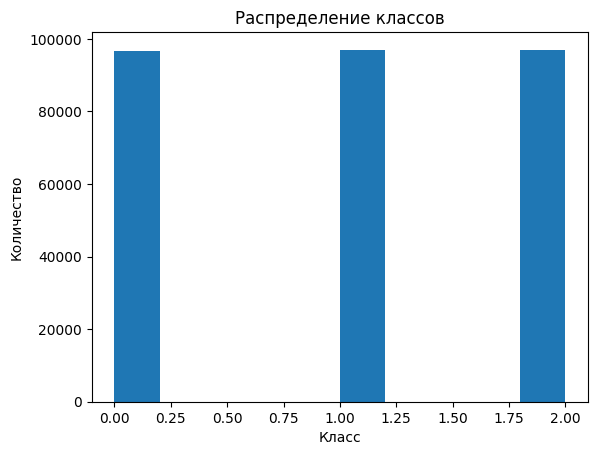

In [ ]:
plt.hist(data['label'])
plt.title('Распределение классов')
plt.xlabel('Класс')
plt.ylabel('Количество')
plt.show()

In [ ]:
data['label'].value_counts()

,count
label,
2,96992
1,96877
0,96589


## Исследование признака src

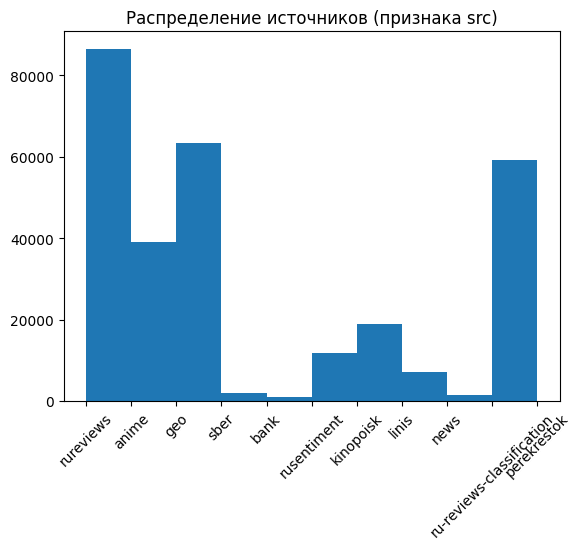

In [ ]:
plt.hist(data['src'])
plt.title('Распределение источников (признака src)')
plt.xticks(rotation=45)
plt.show()

In [ ]:
data.src.value_counts()

,count
src,
rureviews,86436
geo,63408
perekrestok,54462
anime,39027
kinopoisk,18999
rusentiment,11729
linis,7194
ru-reviews-classification,4718
sber,2043


## Физический смысл:  
* text (строковый признак) - первичная информация, последовательность слов. Значимость: максимальная.
* label (целочисленный признак) - целевой признак для обучения с учителем.
* scr (строковый признак) - категория источника. Может влиять на лексику.

## Очистка данных

In [ ]:
def clean_text(text):

    text = text.replace("\\n", " ").replace("\n", " ")
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'[^\w\sа-яА-ЯёЁ0-9!.?:\)\(\[\]\U00010000-\U0010ffff-]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()

data['cleaned_text'] = data['text'].apply(clean_text)
data

,text,label,src,found_emojis,cleaned_text
0,"Пальто красивое, но пришло с дырой в молнии. П...",0,rureviews,[],пальто красивое но пришло с дырой в молнии. пр...
1,"Очень долго шел заказ,ждала к новому году,приш...",0,rureviews,[],очень долго шел заказждала к новому годупришел...
2,"Могу сказать одно, брюки нормальные, НО они бы...",0,rureviews,[],могу сказать одно брюки нормальные но они были...
3,"Доставка быстрая, меньше месяца. Заказывали ра...",0,rureviews,[],доставка быстрая меньше месяца. заказывали раз...
4,Мне не очень понравилось это платье. Размер ...,0,rureviews,[],мне не очень понравилось это платье. размер l ...
...,...,...,...,...,...
290453,Как всегда вкусный и свежий.,1,perekrestok,[],как всегда вкусный и свежий.
290454,Обалденный!,1,perekrestok,[],обалденный!
290455,"Достоинства:\nВкусно, лучшая паста\n\nНедостат...",1,perekrestok,[],достоинства: вкусно лучшая паста недостатки: д...
290456,"Достоинства:\nУвлажняет очень хорошо, и кожа к...",1,perekrestok,[😂],достоинства: увлажняет очень хорошо и кожа как...


## Отчет по пункту:
* Был загружен датасет.
* Проведен анализ на наличие пропущенных значений и эмодзи.
* Проведены анализы распределений данных по источникам в src и классов.
* Оговорен физический смысл данных.
* Проведена очистка текста от лишних пробелв и символов, не являющихся кириллицей, цифрами и эмодзи.

# 3.  
В качестве преобразования сделаем лемматизацию и токенизацию слов в текстах, а затем дальнейшую векторизацию.

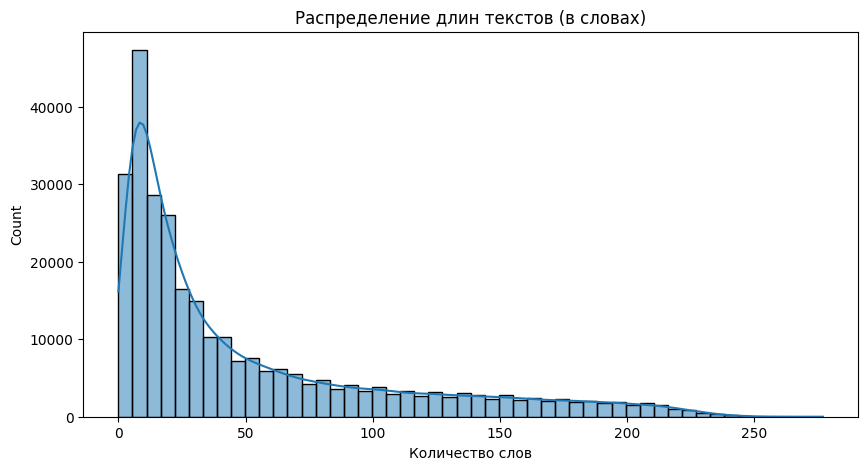

95% текстов имеют длину меньше или равную 180 слов.


In [ ]:
len_count = data.cleaned_text.str.split().str.len()
plt.figure(figsize=(10, 5))
sns.histplot(len_count, bins=50, kde=True)
plt.title('Распределение длин текстов (в словах)')
plt.xlabel('Количество слов')
plt.show()

# Определение квантиля 95%
max_len_val = int(len_count.quantile(0.95))
print(f"95% текстов имеют длину меньше или равную {max_len_val} слов.")

In [ ]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

morph = pymorphy3.MorphAnalyzer()

@lru_cache(maxsize=50_000)
def lemmatize_word(word):
    if word.isalpha():
        return morph.parse(word)[0].normal_form
    return word

def tokenize(text):
    tokens = re.findall(r'\w+|[^\w\s]', text)
    return [lemmatize_word(t) for t in tokens]

all_lemmas = []
for text in data['cleaned_text']:
    all_lemmas.extend(tokenize(text))

token_counts = Counter(all_lemmas)
vocab = {token: i+2 for i, (token, _) in enumerate(token_counts.most_common(30000))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

def vectorization(text, max_len=max_len_val):
    lemmas = tokenize(text)

    if len(lemmas) > max_len:
        lemmas = lemmas[:max_len]

    indexed = [vocab.get(l, 1) for l in lemmas]

    indexed += [vocab['<PAD>']] * (max_len - len(indexed))
    return indexed

data['vectorized'] = data['cleaned_text'].apply(vectorization)

data.head()

,text,label,src,found_emojis,cleaned_text,vectorized
0,"Пальто красивое, но пришло с дырой в молнии. П...",0,rureviews,[],пальто красивое но пришло с дырой в молнии. пр...,"[1685, 182, 13, 83, 11, 1451, 5, 1880, 2, 526,..."
1,"Очень долго шел заказ,ждала к новому году,приш...",0,rureviews,[],очень долго шел заказждала к новому годупришел...,"[18, 262, 157, 1, 29, 165, 1, 85, 75, 4, 1, 2,..."
2,"Могу сказать одно, брюки нормальные, НО они бы...",0,rureviews,[],могу сказать одно брюки нормальные но они были...,"[52, 78, 44, 1432, 297, 13, 27, 14, 3406, 3, 1..."
3,"Доставка быстрая, меньше месяца. Заказывали ра...",0,rureviews,[],доставка быстрая меньше месяца. заказывали раз...,"[154, 309, 119, 186, 2, 164, 66, 505, 20, 83, ..."
4,Мне не очень понравилось это платье. Размер ...,0,rureviews,[],мне не очень понравилось это платье. размер l ...,"[10, 4, 18, 71, 12, 245, 2, 66, 505, 195, 1050..."


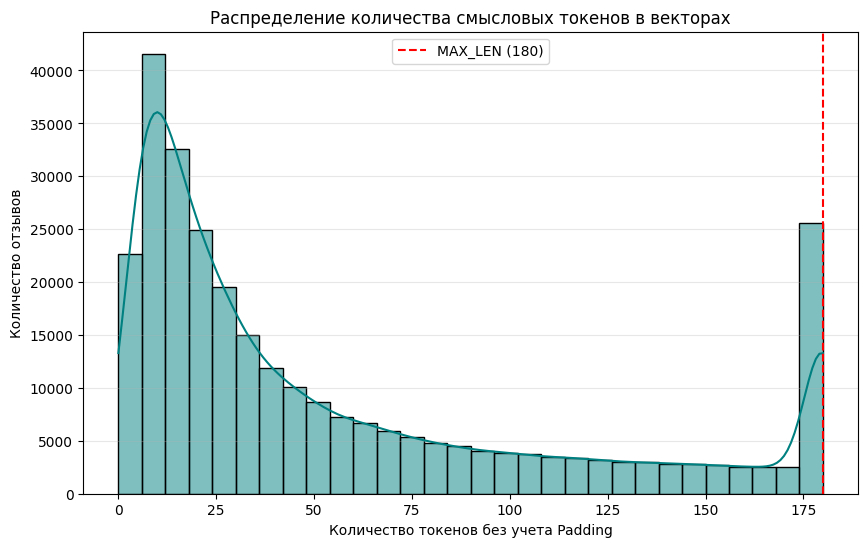

Средняя длина текста: 56.13 токенов
Медианная длина текста: 31.00 токенов
Максимально возможная длина (ограничение): 180 токенов


In [ ]:
vec_len = data['vectorized'].apply(lambda x: len([i for i in x if i != 0]))

plt.figure(figsize=(10, 6))

sns.histplot(vec_len, bins=30, kde=True, color='teal')

plt.axvline(x=max_len_val, color='red', linestyle='--', label=f'MAX_LEN ({max_len_val})')

plt.title('Распределение количества смысловых токенов в векторах')
plt.xlabel('Количество токенов без учета Padding')
plt.ylabel('Количество отзывов')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

print(f"Средняя длина текста: {vec_len.mean():.2f} токенов")
print(f"Медианная длина текста: {vec_len.median():.2f} токенов")
print(f"Максимально возможная длина (ограничение): {max_len_val} токенов")

## Отчет по пункту:
* Проведен просмотр длин последовательностей в данных для примерного подбора значения max_length для проведения обрезания или паддинга при токенизации.
* Далее была проведена непосредственно лемматизация, токенизация и векторизация с помощью ручной реализации токенайзера.

# 4.

In [ ]:
train_df, temp_df = train_test_split(
    data,
    test_size=0.2,
    random_state=42,
    stratify=data[['label', 'src']]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df[['label', 'src']]
)

print(f"Размер обучающей выборки: {len(train_df)}")
print(f"Размер валидационной выборки: {len(val_df)}")
print(f"Размер тестовой выборки: {len(test_df)}")

Размер обучающей выборки: 232366
Размер валидационной выборки: 29046
Размер тестовой выборки: 29046


## Отчет по пункту:
* Данные были разделены на обучающую, тестовую и валидационную выборки с сохранением исходных пропорций распределения по признакам label и src с помощью стратификации. Дисбаланс источников сохраняется во всех выборках. Это является осознанным ограничением: модель обучается на естественном распределении данных. Для минимизации рисков игнорирования редких доменов в Пункте 6 будет применена взвешенная функция потерь Weighted CrossEntropy.

# 5-6.

## Архитектура модели
* Оптимизатор: AdamW  
Самый продвинутый на сегодняшний день.
* Функция потерь: CrossEntropyLoss
* Для работы с данными: LSTM и GRU.  
Это RNN, а значит они учитывают последовательность слов в предложениях, что хорошо для работы с такими данными как отзывы. Также они лучше обычного RNN, так как решают задачу затухания градиента. А двунаправленность позволит проанализировать контекст слов как справа, так и слева.
* Для классификации: 2 линенйых слоя.  
По работе Развана Паскану «On the difficulty of training recurrent neural networks» (2013) первый слой Bi-LSTM извлекает низкоуровневые синтаксические и морфологические признаки, тогда как второй слой формирует более сложные семантические концепции, отвечающие за общую эмоциональную окраску текста.
* Пуллинг для выделения информации: Max Pooling.  
Тональность фразы можно определить по одному-двум ярким словам, поэтому Max Pooling приоритетнее, чем Average в этой задаче. Он выбирает максимальные значения, то есть как раз эти самые яркие и сильные сигналы.

In [ ]:
class CustomSentimentRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers, dropout, rnn_type="LSTM"):
        super(CustomSentimentRNN, self).__init__()

        # 1. Слой эмбеддингов
        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        # 2. Двунаправленный RNN
        if rnn_type == "LSTM":
            self.rnn = nn.LSTM(embedding_dim,
                               hidden_dim,
                               num_layers=n_layers,
                               bidirectional=True,
                               dropout=dropout if n_layers > 1 else 0,
                               batch_first=True)

        elif rnn_type == "GRU":
            self.rnn = nn.GRU(embedding_dim,
                              hidden_dim,
                              num_layers=n_layers,
                              bidirectional=True,
                              dropout=dropout if n_layers > 1 else 0,
                              batch_first=True)

        # 3. Полносвязные слои
        self.fc1 = nn.Linear(hidden_dim * 2, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

        # 4. Регуляризация и активация
        self.dropout = nn.Dropout(dropout)
        self.relu = nn.ReLU()

    def forward(self, text):

        embedded = self.dropout(self.embedding(text))

        output, _ = self.rnn(embedded)

        # Global Max Pooling по всей длине последовательности, чтобы модель заметить самые яркие слова
        pooled, _ = torch.max(output, dim=1)

        x = self.relu(self.fc1(pooled))
        x = self.dropout(x)
        return self.fc2(x)

## Возможные улучшения, если модель окажется плохой:
* Добавление механизма внимания.
* Гибридизация модели. Создание модели: CNN + LSTM/GRU.

## Отчет по пункту:
* Была предложена архитектура модели:
  1. Векторизация с помощью nn.Embedding и выполнение DropOut
  2. Прогон данных через LSTM/GRU
  3. Max Pooling
  4. Прогон через первый полносвязный слой и примение ReLU
  5. DropOut
  6. Прогон через второй полносвязный слой
* Были предложены улучшения


# 7-8.

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Метрики
train_acc_metric = MulticlassAccuracy(num_classes=3, average='micro').to(device)
train_f1_metric = MulticlassF1Score(num_classes=3, average='macro').to(device)

val_acc_metric = MulticlassAccuracy(num_classes=3, average='micro').to(device)
val_f1_metric = MulticlassF1Score(num_classes=3, average='macro').to(device)

Создадим отдельный класс датасета для дополнительной работы с дисбалансом. Дисбаланс присутствует не в целевой переменной, поэтому не получиться просто сделать CrossEntropyLoss с передачей в него весов. Вместо этого проводим взвешивание src и будем отдельно домножать ошибку на вес при обучении, а затем усреднять.  

In [ ]:
class SentimentDataset(Dataset):
    def __init__(self, sequences, labels, weights=None):
        self.sequences = torch.tensor(sequences, dtype=torch.long)
        self.labels = torch.tensor(labels.values, dtype=torch.long)
        # Если веса не переданы (это касается теста и валидации), используем единицы
        if weights is not None:
            self.weights = torch.tensor(weights.values, dtype=torch.float)
        else:
            self.weights = torch.ones(len(labels), dtype=torch.float)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx], self.weights[idx]

sample_weights_src = compute_sample_weight(class_weight='balanced', y=train_df['src'])
train_df['sample_weight'] = sample_weights_src

print("Пример весов для разных источников:")
print(train_df.groupby('src')['sample_weight'].first())

BATCH_SIZE = 128

train_dataset = SentimentDataset(train_df['vectorized'].tolist(), train_df['label'], train_df['sample_weight'])
val_dataset = SentimentDataset(val_df['vectorized'].tolist(), val_df['label'])
test_dataset = SentimentDataset(test_df['vectorized'].tolist(), test_df['label'])

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

Пример весов для разных источников:
src
anime                         0.676602
bank                         28.507668
geo                           0.416429
kinopoisk                     1.389932
linis                         3.671217
news                         17.386158
perekrestok                   0.484844
ru-reviews-classification     5.597292
rureviews                     0.305483
rusentiment                   2.251325
sber                         12.927896
Name: sample_weight, dtype: float64


In [ ]:
VOCAB_SIZE = len(vocab)
model = CustomSentimentRNN(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=256,
    output_dim=3,
    n_layers=2,
    dropout=0.5,
    rnn_type="LSTM"
).to(device)

optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
criterion_train_none = nn.CrossEntropyLoss(reduction='none') # reduction='none', для работы с весами
criterion_val = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer, device):
    model.train()
    total_loss = 0
    train_acc_metric.reset()
    train_f1_metric.reset()

    for inputs, labels, sample_weights in loader:
        inputs, labels, sample_weights = inputs.to(device), labels.to(device), sample_weights.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)

        raw_loss = criterion_train_none(outputs, labels)
        weighted_loss = (raw_loss * sample_weights).mean()

        weighted_loss.backward()
        optimizer.step()

        total_loss += weighted_loss.item()
        train_acc_metric.update(outputs, labels)
        train_f1_metric.update(outputs, labels)

    return total_loss / len(loader), train_acc_metric.compute().item(), train_f1_metric.compute().item()


def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    val_acc_metric.reset()
    val_f1_metric.reset()

    with torch.no_grad():
        for inputs, labels, _ in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            val_acc_metric.update(outputs, labels)
            val_f1_metric.update(outputs, labels)

    return total_loss / len(loader), val_acc_metric.compute().item(), val_f1_metric.compute().item()

EPOCHS = 10
history = {
    'train_loss': [], 'train_acc': [], 'train_f1': [],
    'val_loss': [], 'val_acc': [], 'val_f1': []
}

for epoch in range(EPOCHS):
    t_loss, t_acc, t_f1 = train_one_epoch(model, train_loader, optimizer, device)
    v_loss, v_acc, v_f1 = validate_one_epoch(model, val_loader, criterion_val, device)

    history['train_loss'].append(t_loss); history['train_acc'].append(t_acc); history['train_f1'].append(t_f1)
    history['val_loss'].append(v_loss); history['val_acc'].append(v_acc); history['val_f1'].append(v_f1)

    print(f"Epoch {epoch+1}/{EPOCHS}:")
    print(f"  [Train] Loss: {t_loss:.4f} | Acc: {t_acc:.4f} | F1: {t_f1:.4f}")
    print(f"  [Val]   Loss: {v_loss:.4f} | Acc: {v_acc:.4f} | F1: {v_f1:.4f}")

Epoch 1/10:
  [Train] Loss: 0.9560 | Acc: 0.5422 | F1: 0.5342
  [Val]   Loss: 0.8481 | Acc: 0.6011 | F1: 0.5902
Epoch 2/10:
  [Train] Loss: 0.8332 | Acc: 0.6349 | F1: 0.6337
  [Val]   Loss: 0.7112 | Acc: 0.6617 | F1: 0.6616
Epoch 3/10:
  [Train] Loss: 0.7848 | Acc: 0.6600 | F1: 0.6594
  [Val]   Loss: 0.6964 | Acc: 0.6830 | F1: 0.6786
Epoch 4/10:
  [Train] Loss: 0.7444 | Acc: 0.6753 | F1: 0.6755
  [Val]   Loss: 0.6690 | Acc: 0.6959 | F1: 0.6993
Epoch 5/10:
  [Train] Loss: 0.7214 | Acc: 0.6837 | F1: 0.6842
  [Val]   Loss: 0.6745 | Acc: 0.6972 | F1: 0.6943
Epoch 6/10:
  [Train] Loss: 0.6976 | Acc: 0.6906 | F1: 0.6915
  [Val]   Loss: 0.6539 | Acc: 0.7048 | F1: 0.7056
Epoch 7/10:
  [Train] Loss: 0.6739 | Acc: 0.6971 | F1: 0.6977
  [Val]   Loss: 0.6505 | Acc: 0.7068 | F1: 0.7071
Epoch 8/10:
  [Train] Loss: 0.6582 | Acc: 0.7008 | F1: 0.7012
  [Val]   Loss: 0.6516 | Acc: 0.7073 | F1: 0.7056
Epoch 9/10:
  [Train] Loss: 0.6425 | Acc: 0.7056 | F1: 0.7060
  [Val]   Loss: 0.6435 | Acc: 0.7065 | F1:

По итогам обучения можно сказать, что поставленной цели в 0.85 не получилось достичь, однако все равно результаты демонстрируют работоспособность подхода.  
* Во-первых, 0.7 - это неплохой средний показатель, особенно с учетом сложности задачи: классов 3, а не 2. Плюс модель видит какие-либо закономерности, а не просто угадывает.
* Во-вторых, при сравнении метрик на train и val можно сказть об отсутствии переобучения, что говорит о потенциале модели.

## Отчет по пункту:
* Были инициализированны метрики и отслеживания того, какое используется устройство
* Проведены приготовления для работы с дисбалансом в src и разбиение данных на батчи.
* Проведено обучение модели и оценка ее качества

# 9.

## BaseLine и модификации архитектуры
* В качестве BaseLine оценим важность слова по принимитивному TF-IDF, а затем обучим логистическую регрессию.
* Альтернативы:
    1. LSTM с 3 слоями. Попробуем сильнее углубить модель.
    2. Архитектуру CustomSentimentRNN с GRU. GRU проще обучать и может дать результат лучше LSTM.  
Здесь проведем обучение на 5, а не 10 эпохах. Это позволит сэкономить время, но при этом все равно сделать выводы об обучаемости моделей.

In [ ]:
all_histories = {}

all_histories['2-layer Bi-LSTM (Main)'] = history

# Функция для запуска нейросетевых экспериментов с сохранением истории
def run_nn_experiment(model_config, name, epochs=5):
    print(f"\n--- [Запуск: {name}] ---")

    model = CustomSentimentRNN(**model_config).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # Локальная история для текущей модели
    exp_history = {
        'train_loss': [], 'train_acc': [], 'train_f1': [],
        'val_loss': [], 'val_acc': [], 'val_f1': []
    }

    for epoch in range(epochs):
        t_loss, t_acc, t_f1 = train_one_epoch(model, train_loader, optimizer, device)
        v_loss, v_acc, v_f1 = validate_one_epoch(model, val_loader, criterion_val, device)

        exp_history['train_loss'].append(t_loss)
        exp_history['train_acc'].append(t_acc)
        exp_history['train_f1'].append(t_f1)
        exp_history['val_loss'].append(v_loss)
        exp_history['val_acc'].append(v_acc)
        exp_history['val_f1'].append(v_f1)

        print(f"Epoch {epoch+1} | Val Acc: {v_acc:.4f} | Val F1: {v_f1:.4f}")

    return exp_history

# Список для итоговой таблицы
comparison_results = []

# Сразу добавим результаты первой модели
comparison_results.append({
    'Model': '2-layer Bi-LSTM (Main)',
    'Acc': max(history['val_acc']),
    'F1': max(history['val_f1'])
})

# --- ЭКСПЕРИМЕНТ 1: Baseline (LogReg + TF-IDF) ---
print("--- [Запуск: Baseline (LogReg + TF-IDF)] ---")
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(train_df['cleaned_text'])
X_test_tfidf = tfidf.transform(test_df['cleaned_text'])

baseline_sample_weights = compute_sample_weight(class_weight='balanced', y=train_df['src'])

baseline_model = LogisticRegression(max_iter=1000, solver='lbfgs')
baseline_model.fit(X_train_tfidf, train_df['label'], sample_weight=baseline_sample_weights)
baseline_preds = baseline_model.predict(X_test_tfidf)

b_acc = accuracy_score(test_df['label'], baseline_preds)
b_f1 = f1_score(test_df['label'], baseline_preds, average='macro')

comparison_results.append({'Model': 'Baseline (LogReg)', 'Acc': b_acc, 'F1': b_f1})
# У логрега нет эпох, но для графиков создадим плоскую историю
all_histories['Baseline'] = {'val_f1': [b_f1] * 5, 'val_acc': [b_acc] * 5}

# --- ЭКСПЕРИМЕНТ 2: 3-layer Bi-LSTM (Глубокая) ---
config_3 = {
    'vocab_size': len(vocab), 'embedding_dim': 128, 'hidden_dim': 256,
    'output_dim': 3, 'n_layers': 3, 'dropout': 0.5, 'rnn_type': 'LSTM'
}
history_3 = run_nn_experiment(config_3, "3-layer Bi-LSTM")
all_histories['3-layer Bi-LSTM'] = history_3
comparison_results.append({
    'Model': '3-layer Bi-LSTM',
    'Acc': max(history_3['val_acc']),
    'F1': max(history_3['val_f1'])
})

# --- ЭКСПЕРИМЕНТ 4: 2-layer Bi-GRU (Альтернативная) ---
config_4 = {
    'vocab_size': len(vocab), 'embedding_dim': 128, 'hidden_dim': 256,
    'output_dim': 3, 'n_layers': 2, 'dropout': 0.5, 'rnn_type': 'GRU'
}
history_4 = run_nn_experiment(config_4, "2-layer Bi-GRU")
all_histories['2-layer Bi-GRU'] = history_4
comparison_results.append({
    'Model': '2-layer Bi-GRU',
    'Acc': max(history_4['val_acc']),
    'F1': max(history_4['val_f1'])
})

df_results = pd.DataFrame(comparison_results)
print("\nИТОГОВАЯ ТАБЛИЦА СРАВНЕНИЯ:")
print(df_results.sort_values(by='F1', ascending=False))

--- [Запуск: Baseline (LogReg + TF-IDF)] ---

--- [Запуск: 3-layer Bi-LSTM] ---
Epoch 1 | Val Acc: 0.6016 | Val F1: 0.5875
Epoch 2 | Val Acc: 0.6606 | Val F1: 0.6558
Epoch 3 | Val Acc: 0.6670 | Val F1: 0.6546
Epoch 4 | Val Acc: 0.6889 | Val F1: 0.6919
Epoch 5 | Val Acc: 0.6896 | Val F1: 0.6803

--- [Запуск: 2-layer Bi-GRU] ---
Epoch 1 | Val Acc: 0.6251 | Val F1: 0.6217
Epoch 2 | Val Acc: 0.6739 | Val F1: 0.6684
Epoch 3 | Val Acc: 0.6749 | Val F1: 0.6759
Epoch 4 | Val Acc: 0.6957 | Val F1: 0.6997
Epoch 5 | Val Acc: 0.6962 | Val F1: 0.6997

ИТОГОВАЯ ТАБЛИЦА СРАВНЕНИЯ:
                    Model       Acc        F1
0  2-layer Bi-LSTM (Main)  0.707257  0.708596
3          2-layer Bi-GRU  0.696172  0.699685
2         3-layer Bi-LSTM  0.689630  0.691916
1       Baseline (LogReg)  0.686463  0.686701


По результатам обучения можно сказать, что архитектура в целом показала себя лучше, чем BaseLine в виде логистической регрессии. Из всех же моделей самой успешной можно назвать GRU. Хоть эпох и было 5, видно, что ее рост быстрее других моделей. В следующем пункте буду использовать именно ее.

## Отчет по пункту:
* Были реализованы BaseLine и модификации архитектуры с другими параметрами и проведены их оценки

# 10.

При проведении Grid Search проварьируем размерность скрытого состояния, скорость обучения и вероятность dropout

In [ ]:
def train_one_epoch(model, loader, optimizer, device):
    model.train()
    total_loss = 0
    train_acc_metric.reset()
    train_f1_metric.reset()

    for inputs, labels, sample_weights in loader:
        inputs, labels, sample_weights = inputs.to(device), labels.to(device), sample_weights.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)

        raw_loss = criterion_train_none(outputs, labels)
        weighted_loss = (raw_loss * sample_weights).mean()

        weighted_loss.backward()
        optimizer.step()

        total_loss += weighted_loss.item()
        train_acc_metric.update(outputs, labels)
        train_f1_metric.update(outputs, labels)

    return total_loss / len(loader), train_acc_metric.compute().item(), train_f1_metric.compute().item()


def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    val_acc_metric.reset()
    val_f1_metric.reset()

    with torch.no_grad():
        for inputs, labels, _ in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            val_acc_metric.update(outputs, labels)
            val_f1_metric.update(outputs, labels)

    return total_loss / len(loader), val_acc_metric.compute().item(), val_f1_metric.compute().item()

In [ ]:
hidden_candidates = [128, 256, 512]
lr_candidates = [1e-3, 5e-4]
dropout_candidates = [0.3, 0.5]

criterion_train_none = nn.CrossEntropyLoss(reduction='none')
criterion_val = nn.CrossEntropyLoss()

tuning_results = []

subset_indices = list(range(0, min(50000, len(train_dataset))))
subset_train_loader = DataLoader(
    torch.utils.data.Subset(train_dataset, subset_indices),
    batch_size=BATCH_SIZE, shuffle=True
)

for h_dim in hidden_candidates:
    for lr in lr_candidates:
        for drp in dropout_candidates:
            print(f"Тестирование конфигурации: hidden={h_dim}, lr={lr}, dropout={drp}")

            # Очистка кэша перед созданием новой модели
            gc.collect()
            torch.cuda.empty_cache()

            config = {
                'vocab_size': len(vocab),
                'embedding_dim': 128,
                'hidden_dim': h_dim,
                'output_dim': 3,
                'n_layers': 2,
                'dropout': drp,
                'rnn_type': 'GRU'
            }

            model_t = CustomSentimentRNN(**config).to(device)
            optimizer_t = optim.AdamW(model_t.parameters(), lr=lr)

            # Обучаем 5 эпох для оценки "обучаемости"
            for epoch in range(5):
                _ = train_one_epoch(model_t, subset_train_loader, optimizer_t, device)

            _, v_acc, v_f1 = validate_one_epoch(model_t, val_loader, criterion_val, device)

            tuning_results.append({
                'hidden_dim': h_dim,
                'lr': lr,
                'dropout': drp,
                'val_f1': v_f1,
                'val_acc': v_acc
            })
            print(f"   Результат -> Val Acc: {v_acc:.4f} | Val F1: {v_f1:.4f}")

best_params = max(tuning_results, key=lambda x: x['val_f1'])
print("\n" + "="*30)
print("ПОДБОР ГИПЕРПАРАМЕТРОВ ЗАВЕРШЕН")
print(f"Лучшие параметры по метрике F1: {best_params}")
print("="*30)

Тестирование конфигурации: hidden=128, lr=0.001, dropout=0.3
   Результат -> Val Acc: 0.6549 | Val F1: 0.6568
Тестирование конфигурации: hidden=128, lr=0.001, dropout=0.5
   Результат -> Val Acc: 0.6387 | Val F1: 0.6414
Тестирование конфигурации: hidden=128, lr=0.0005, dropout=0.3
   Результат -> Val Acc: 0.6366 | Val F1: 0.6357
Тестирование конфигурации: hidden=128, lr=0.0005, dropout=0.5
   Результат -> Val Acc: 0.5798 | Val F1: 0.5650
Тестирование конфигурации: hidden=256, lr=0.001, dropout=0.3
   Результат -> Val Acc: 0.6529 | Val F1: 0.6433
Тестирование конфигурации: hidden=256, lr=0.001, dropout=0.5
   Результат -> Val Acc: 0.6359 | Val F1: 0.6317
Тестирование конфигурации: hidden=256, lr=0.0005, dropout=0.3
   Результат -> Val Acc: 0.6262 | Val F1: 0.6278
Тестирование конфигурации: hidden=256, lr=0.0005, dropout=0.5
   Результат -> Val Acc: 0.6087 | Val F1: 0.6050
Тестирование конфигурации: hidden=512, lr=0.001, dropout=0.3
   Результат -> Val Acc: 0.6553 | Val F1: 0.6544
Тестир

По итогу, лучшими параметрами оказались: hidden_dim = 128, lr = 0.001, dropout = 0.3. Обучим новую модель с найденными гиперпараметрами.

In [ ]:
best_config = {
    'vocab_size': len(vocab),
    'embedding_dim': 128,
    'hidden_dim': 128,
    'output_dim': 3,
    'n_layers': 2,
    'dropout': 0.3,
    'rnn_type': 'GRU'
}

tuned_model = CustomSentimentRNN(**best_config).to(device)
optimizer = optim.AdamW(tuned_model.parameters(), lr=0.001, weight_decay=1e-5)
criterion_train_none = nn.CrossEntropyLoss(reduction='none')
criterion_val = nn.CrossEntropyLoss()

history_tuned = {
    'train_loss': [], 'train_acc': [], 'train_f1': [],
    'val_loss': [], 'val_acc': [], 'val_f1': []
}

EPOCHS = 10
for epoch in range(EPOCHS):
    t_loss, t_acc, t_f1 = train_one_epoch(tuned_model, train_loader, optimizer, device)
    v_loss, v_acc, v_f1 = validate_one_epoch(tuned_model, val_loader, criterion_val, device)

    if v_f1 > best_v_f1:
        best_v_f1 = v_f1
        torch.save(tuned_model.state_dict(), 'best_tuned_model.pth')
        print(f"--> Сохранены лучшие веса (Val F1: {v_f1:.4f})")

    history_tuned['train_loss'].append(t_loss)
    history_tuned['train_acc'].append(t_acc)
    history_tuned['train_f1'].append(t_f1)
    history_tuned['val_loss'].append(v_loss)
    history_tuned['val_acc'].append(v_acc)
    history_tuned['val_f1'].append(v_f1)

    print(f"Epoch {epoch+1}/{EPOCHS}:")
    print(f"  [Train] Loss: {t_loss:.4f} | Acc: {t_acc:.4f} | F1: {t_f1:.4f}")
    print(f"  [Val]   Loss: {v_loss:.4f} | Acc: {v_acc:.4f} | F1: {v_f1:.4f}")

--> Сохранены лучшие веса (Val F1: 0.6545)
Epoch 1/10:
  [Train] Loss: 0.9333 | Acc: 0.5653 | F1: 0.5575
  [Val]   Loss: 0.7290 | Acc: 0.6596 | F1: 0.6545
--> Сохранены лучшие веса (Val F1: 0.6785)
Epoch 2/10:
  [Train] Loss: 0.7969 | Acc: 0.6549 | F1: 0.6549
  [Val]   Loss: 0.6926 | Acc: 0.6754 | F1: 0.6785
--> Сохранены лучшие веса (Val F1: 0.6968)
Epoch 3/10:
  [Train] Loss: 0.7301 | Acc: 0.6823 | F1: 0.6823
  [Val]   Loss: 0.6694 | Acc: 0.6940 | F1: 0.6968
--> Сохранены лучшие веса (Val F1: 0.7044)
Epoch 4/10:
  [Train] Loss: 0.6775 | Acc: 0.6966 | F1: 0.6972
  [Val]   Loss: 0.6633 | Acc: 0.7016 | F1: 0.7044
Epoch 5/10:
  [Train] Loss: 0.6339 | Acc: 0.7072 | F1: 0.7079
  [Val]   Loss: 0.6733 | Acc: 0.6989 | F1: 0.6985
Epoch 6/10:
  [Train] Loss: 0.5981 | Acc: 0.7152 | F1: 0.7160
  [Val]   Loss: 0.6844 | Acc: 0.7017 | F1: 0.7000
--> Сохранены лучшие веса (Val F1: 0.7073)
Epoch 7/10:
  [Train] Loss: 0.5648 | Acc: 0.7213 | F1: 0.7215
  [Val]   Loss: 0.6693 | Acc: 0.7096 | F1: 0.7073
-

Вывод: Построенная модель в конечном итоге оказалась лучше, чем модель из пункта 8.

## Отчет по пункту:
* Проведена оценка гиперпараметров архитектуры CustomSentimentRNN с GRU.
* Построена новая модель с лучшими гиперпараметрами.

# 11.

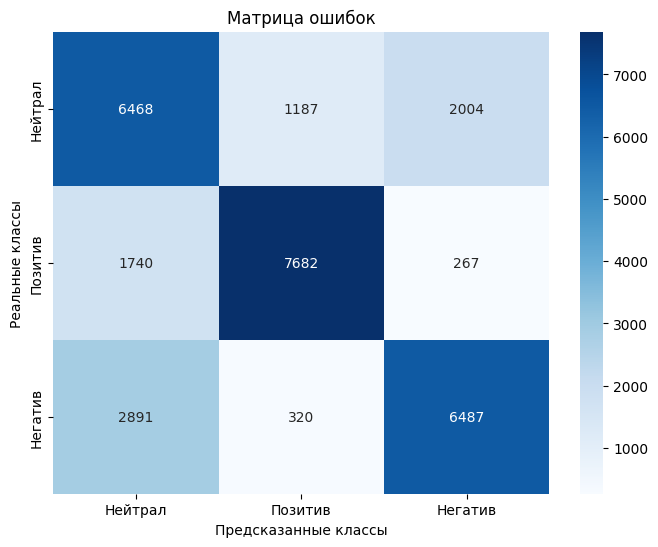


Детальный отчет по метрикам (Test Set):
              precision    recall  f1-score   support

     Нейтрал       0.58      0.67      0.62      9659
     Позитив       0.84      0.79      0.81      9689
     Негатив       0.74      0.67      0.70      9698

    accuracy                           0.71     29046
   macro avg       0.72      0.71      0.71     29046
weighted avg       0.72      0.71      0.71     29046



In [ ]:
def plot_confusion_matrix(model, loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels, _ in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Нейтрал', 'Позитив', 'Негатив'],
                yticklabels=['Нейтрал', 'Позитив', 'Негатив'])
    plt.ylabel('Реальные классы')
    plt.xlabel('Предсказанные классы')
    plt.title('Матрица ошибок')
    plt.show()

    print("\nДетальный отчет по метрикам (Test Set):")
    print(classification_report(all_labels, all_preds, target_names=['Нейтрал', 'Позитив', 'Негатив']))

plot_confusion_matrix(tuned_model, test_loader, device)

Выводы:
1. Самой успешной для модели оказалась классификация Положительных отзывов. Модель верно определила 7682 положительных отзыва. Она крайне редко путает позитив с негативом всего 267 ошибок. Это означает, что нейросеть Bi-GRU отлично выучила лексику одобрения и похвалы.
2. Нейтрал и негатив имеют примерно одинаковое количество корректных распознований, но видна серезная проблема именно с нейтральным классом. Если негатив и позитив различаются относительно хорошо, то вот в случае нейтрала модель очень часто путает классы, особенно это видно в случае с негативом. 2004 объекта нейтрала было определено как негатив и 2891 объектов негатива было определено как нейтрал.
  
Общий вывод: Это указывает на «осторожность» модели. Она часто не распознает скрытое недовольство или вежливые жалобы, относя их к нейтральному информационному фону, и наоборот.

In [ ]:
def get_error_examples(model, loader, device, vocab_inv, num_examples=3):
    model.eval()
    errors = {
        'Neg_as_Neu': [],
        'Neu_as_Neg': [],
        'Neg_as_Pos'  : []
    }

    with torch.no_grad():
        for inputs, labels, _ in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for i in range(len(labels)):
                true_lab = labels[i].item()
                pred_lab = preds[i].item()

                text = " ".join([vocab_inv.get(idx.item(), "") for idx in inputs[i] if idx.item() > 1])

                if true_lab == 2 and pred_lab == 0 and len(errors['Neg_as_Neu']) < num_examples:
                    errors['Neg_as_Neu'].append(text)
                if true_lab == 0 and pred_lab == 2 and len(errors['Neu_as_Neg']) < num_examples:
                    errors['Neu_as_Neg'].append(text)
                if true_lab == 2 and pred_lab == 1 and len(errors['Neg_as_Pos']) < num_examples:
                    errors['Neg_as_Pos'].append(text)

    return errors

vocab_inv = {v: k for k, v in vocab.items()}
error_samples = get_error_examples(tuned_model, test_loader, device, vocab_inv)

print("ПРИМЕРЫ ОШИБОК ДЛЯ АНАЛИЗА:")
for error_type, texts in error_samples.items():
    print(f"\nТип ошибки: {error_type}")
    for t in texts:
        print(f"- {t}")

ПРИМЕРЫ ОШИБОК ДЛЯ АНАЛИЗА:

Тип ошибки: Neg_as_Neu
- номер я зарезервировать но когда приехать в ночь некуда быть припарковать машина . на телефон отвечать автоответчик . в общий развернуться и в ночь уехать в другой отель . хорошо что не сезон и в друг отель номер свободный быть много .
- итак написать вы почему стоить смотреть данный каждый определить для себя сам . для начало о рисовка так как она интересовать многий . она - довольно своеобразный 3д хоть и не голливудский но и не вырвиглазной вспомнить тот же берсерка . о сюжет можно сказать пара слово пара слово теперь кама . сюжет - неплохой хоть и довольно предсказуемый и напичкать клише смотреть не напряжный . персонаж не сильный но и не слабый твёрдый такой среднячок . в целое - довольно достойный произведение есть пара серия который можно посмотреть за 5 минута - в остальной практически всё интересно не особо захватывать но и скучать не заставить . идея прекрасный но хотеться бы большой лор . на это всё .
- оригинал взять у в

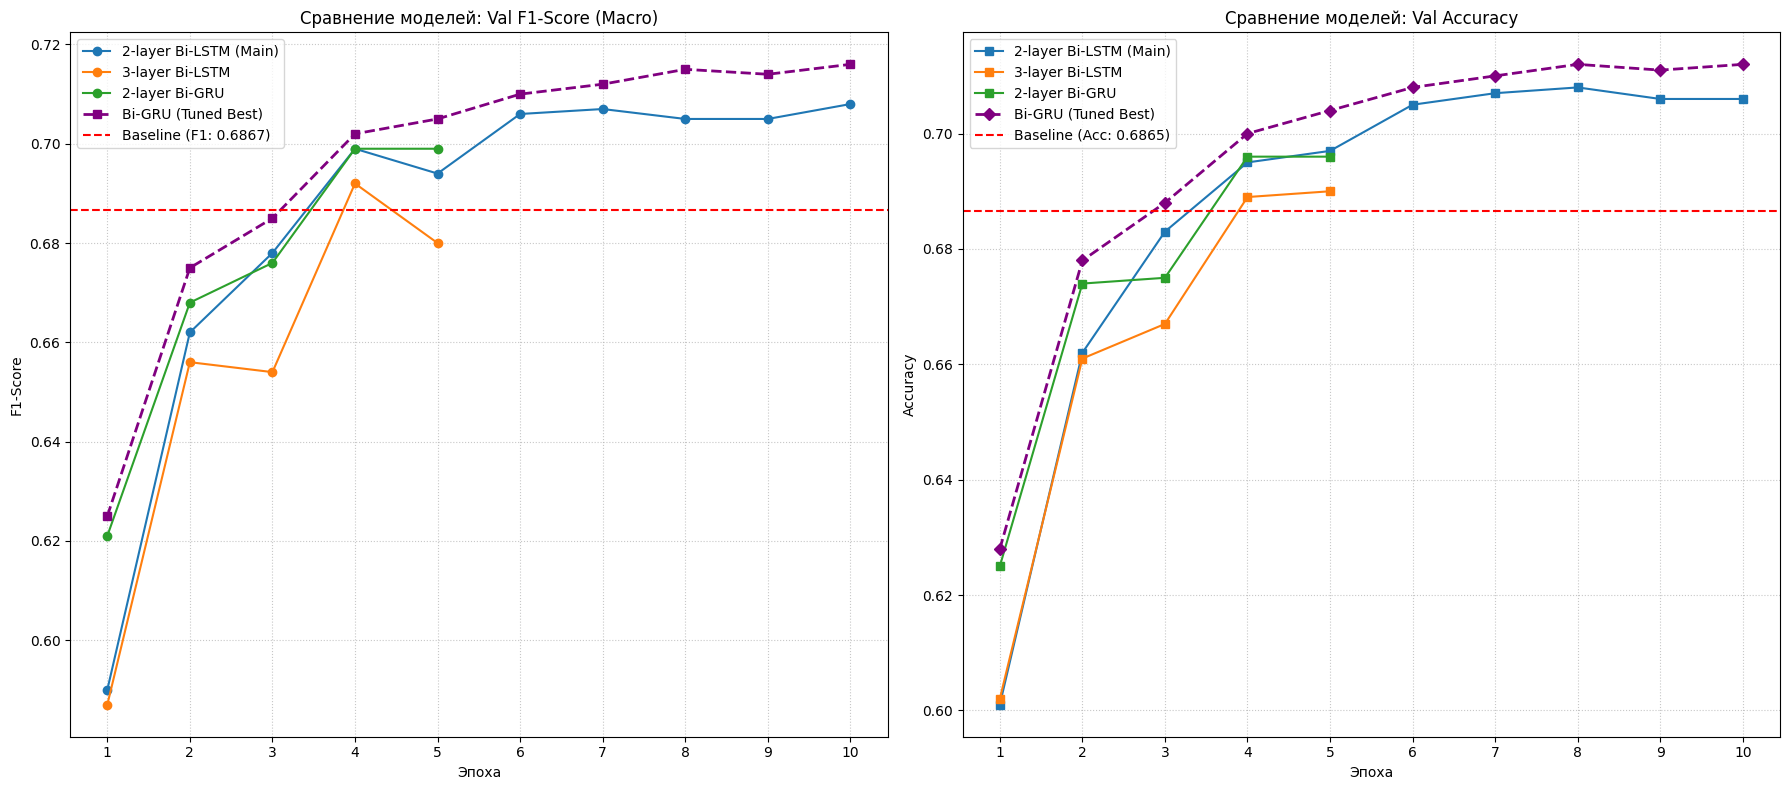

In [ ]:
def plot_all_models_comparison(all_histories, baseline_f1, baseline_acc):

    plt.figure(figsize=(16, 7))

    plt.subplot(1, 2, 1)
    for model_name, history in all_histories.items():
        if model_name == 'Baseline':
            continue

        y_values = history['val_f1']
        x_values = range(1, len(y_values) + 1)

        plt.plot(x_values, y_values, marker='o', label=f'{model_name}')

    plt.axhline(y=baseline_f1, color='red', linestyle='--', label=f'Baseline (F1: {baseline_f1:.4f})')

    plt.title('Сравнение моделей: Val F1-Score (Macro)')
    plt.xlabel('Эпоха')
    plt.ylabel('F1-Score')
    plt.xticks(range(1, 11))
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend()

    plt.subplot(1, 2, 2)
    for model_name, history in all_histories.items():
        if model_name == 'Baseline':
            continue

        y_values = history['val_acc']
        x_values = range(1, len(y_values) + 1)

        plt.plot(x_values, y_values, marker='s', label=f'{model_name}')

    plt.axhline(y=baseline_acc, color='red', linestyle='--', label=f'Baseline (Acc: {baseline_acc:.4f})')

    plt.title('Сравнение моделей: Val Accuracy')
    plt.xlabel('Эпоха')
    plt.ylabel('Accuracy')
    plt.xticks(range(1, 11))
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_all_models_comparison(all_histories, b_f1, b_acc)

Анализ кривых обучения позволяет сделать выводы:
* Все протестированные конфигурации продемонстрировали более высокие показатели, чем Baseline. Это подтверждает, что для анализа тональности учёт контекстуальных связей и последовательности слов важнее простой частотности термов (TF-IDF).
* Наилучший результат показала 2-layer Bi-GRU, достигнув на 10-й эпохе значения F1 и accuracy ≈ 0.71.
* Увеличение количества слоёв до трёх привело к ухудшению результатов по сравнению с 2-слойными моделями. Это свидетельствует об избыточности параметров и риске переобучения: для текстов средней длины два рекуррентных слоя являются оптимальным архитектурным решением.

Итоговые выводы и рекомендации:
* Модель Bi-GRU эффективно решает задачу классификации лояльных отзывов, что, например, позволит использовать её для автоматического выделения лучших практик сервиса.
* Основная проблема модели — слабая чувствительность к негативу и нейтралу. Значительная доля пропущенных жалоб, определенных как «Нейтрал», говорит о том, что модель не обладает достаточной чувствительностью к структуре претензии, если в ней нет «кричащих» слов-маркеров.  

Рекомендации:
* Попробовать гибридные модели и/или ввести механизм внимания.
* Ошибки между нейтральным и негативным классами показывают, что модели не хватает понимания контекста отрицаний. Можно использовать предобученные эмбеддинги, чтобы лучше разделять факты и скрытое недовольство.
* Для практического применения стоит снизить порог для отнесения текста к негативному классу, чтобы минимизировать пропуск жалоб клиентов.

## Отчет по пункту:
* Выведена матрица ошибок самой первой модели.
* Проиллюстрированы метрики модели по конкретным меткам классов
* Визуализированы графики обучения всех моделей